In [ ]:
def gerar_relatorio(df):
    print("=" * 55)
    print("       RELATÓRIO FINAL - ANÁLISE DA BASE VAREJO")
    print("=" * 55)


    print("\n1. INFORMAÇÕES GERAIS")
    print("-" * 35)
    print(f"Total de registros: {len(df)}")
    print(f"Total de colunas: {len(df.columns)}")

    if 'CL_ID' in df.columns:
        print(f"Clientes únicos: {df['CL_ID'].nunique()}")

    if 'PR_ID' in df.columns:
        print(f"Produtos únicos: {df['PR_ID'].nunique()}")

    if 'PR_CAT' in df.columns:
        print(f"Categorias de produtos: {df['PR_CAT'].nunique()}")

    
    if 'DATA' in df.columns:
        datas = pd.to_datetime(df['DATA'], errors='coerce')
        print("\n2. PERÍODO DOS DADOS")
        print("-" * 35)

        if datas.notna().any():
            print(f"Data inicial: {datas.min():%d/%m/%Y}")
            print(f"Data final: {datas.max():%d/%m/%Y}")
        else:
            print("Não foi possível identificar datas válidas.")

   
    print("\n3. QUALIDADE DOS DADOS")
    print("-" * 35)
    print(f"Total de valores ausentes: {df.isna().sum().sum()}")
    print(f"Total de linhas duplicadas: {df.duplicated().sum()}")

    
    if 'CL_FHL' in df.columns:
        filhos = pd.to_numeric(df['CL_FHL'], errors='coerce').dropna()

        print("\n4. NÚMERO DE FILHOS DOS CLIENTES")
        print("-" * 35)

        if not filhos.empty:
            print(f"Registros válidos: {filhos.count()}")
            print(f"Média: {filhos.mean():.2f}")
            print(f"Mediana: {filhos.median():.2f}")
            print(f"Moda: {filhos.mode().tolist()}")
            print(f"Mínimo: {filhos.min()}")
            print(f"Máximo: {filhos.max()}")
            print(f"Desvio padrão: {filhos.std():.2f}")
        else:
            print("Não existem valores válidos para análise.")

    
    if 'PR_CAT' in df.columns:
        print("\n5. TOP 10 CATEGORIAS POR REGISTROS")
        print("-" * 35)
        print(df['PR_CAT'].value_counts().head(10).to_string())

    print("\n" + "=" * 55)
    print("Relatório concluído.")
    print("=" * 55)



gerar_relatorio(df_limpo)

       RELATÓRIO FINAL - ANÁLISE DA BASE VAREJO

1. INFORMAÇÕES GERAIS
-----------------------------------
Total de registros: 830000
Total de colunas: 10
Clientes únicos: 1000
Produtos únicos: 229
Categorias de produtos: 7

2. PERÍODO DOS DADOS
-----------------------------------
Data inicial: 02/01/2019
Data final: 12/08/2022

3. QUALIDADE DOS DADOS
-----------------------------------
Total de valores ausentes: 0
Total de linhas duplicadas: 96553

4. NÚMERO DE FILHOS DOS CLIENTES
-----------------------------------
Registros válidos: 830000
Média: 1.15
Mediana: 0.00
Moda: [0]
Mínimo: 0
Máximo: 4
Desvio padrão: 1.42

5. TOP 10 CATEGORIAS POR REGISTROS
-----------------------------------
PR_CAT
ALIMENTOS     434767
HIGIENE       155574
LIMPEZA       145754
BEBIDAS        43299
PET            32399
ACESSORIOS     14557
#N/D            3650

Relatório concluído.


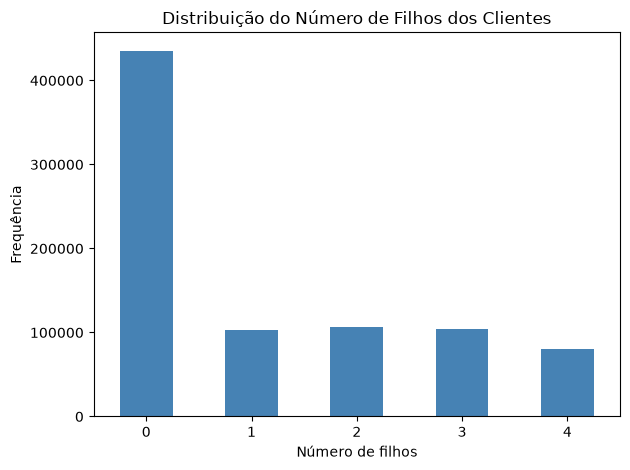

In [72]:
import matplotlib.pyplot as plt

frequencia = df_limpo['CL_FHL'].value_counts().sort_index()

frequencia.plot(kind='bar', color='steelblue')

plt.title('Distribuição do Número de Filhos dos Clientes')
plt.xlabel('Número de filhos')
plt.ylabel('Frequência')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [69]:


%pip install matplotlib



Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [63]:
percentual = (
    df_limpo['CL_FHL']
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(percentual.round(2))

CL_FHL
0    52.47
1    12.39
2    12.85
3    12.61
4     9.68
Name: proportion, dtype: float64


In [62]:
frequencia = df_limpo['CL_FHL'].value_counts().sort_index()

print(frequencia)

CL_FHL
0    435501
1    102813
2    106622
3    104685
4     80379
Name: count, dtype: int64


In [61]:
df_limpo['CL_FHL'].describe()

count    830000.00000
mean          1.14654
std           1.41696
min           0.00000
25%           0.00000
50%           0.00000
75%           2.00000
max           4.00000
Name: CL_FHL, dtype: float64

In [ ]:

print("ESTATÍSTICA DESCRITIVA - NÚMERO DE FILHOS")
print("------------------------------------------")

print("Quantidade de registros válidos:", filhos.count())
print("Quantidade de valores ausentes:", filhos.isna().sum())
print("Média:", filhos.mean())
print("Mediana:", filhos.median())
print("Moda:", filhos.mode().tolist())
print("Mínimo:", filhos.min())
print("Máximo:", filhos.max())
print("Variância:", filhos.var())
print("Desvio padrão:", filhos.std())
print("Primeiro quartil (Q1):", filhos.quantile(0.25))
print("Segundo quartil (Q2):", filhos.quantile(0.50))
print("Terceiro quartil (Q3):", filhos.quantile(0.75))

ESTATÍSTICA DESCRITIVA - NÚMERO DE FILHOS
------------------------------------------
Quantidade de registros válidos: 830000
Quantidade de valores ausentes: 0
Média: 1.1465397590361446
Mediana: 0.0
Moda: [0]
Mínimo: 0
Máximo: 4
Variância: 2.007774301159341
Desvio padrão: 1.4169595270011563
Primeiro quartil (Q1): 0.0
Segundo quartil (Q2): 0.0
Terceiro quartil (Q3): 2.0


In [76]:
filhos = pd.to_numeric(df_limpo['CL_FHL'], errors='coerce')

In [58]:
print(df_limpo['CL_FHL'].head(10))
print(df_limpo['CL_FHL'].dtype)

0    1
1    1
2    1
3    1
4    1
5    1
6    1
7    1
8    1
9    1
Name: CL_FHL, dtype: int64
int64


In [ ]:

df_limpo = df_limpo.dropna(axis=1, how='all')

print("Colunas restantes:")
print(df_limpo.columns.tolist())

print(df_limpo.head())

Colunas restantes:
['DATA', 'CO_ID', 'CL_ID', 'CL_GENERO', 'CL_EC', 'CL_FHL', 'CL_SEG', 'PR_ID', 'PR_CAT', 'PR_NOME']
         DATA  CO_ID  CL_ID CL_GENERO  CL_EC  CL_FHL CL_SEG  PR_ID     PR_CAT  \
0  01/02/2019   1000    534         M      4       1      C     67    BEBIDAS   
1  01/02/2019   1000    534         M      4       1      C     70    BEBIDAS   
2  01/02/2019   1000    534         M      4       1      C    178    HIGIENE   
3  01/02/2019   1000    534         M      4       1      C      4  ALIMENTOS   
4  01/02/2019   1000    534         M      4       1      C    175    LIMPEZA   

                PR_NOME  
0  REFRIGERANTE GUARANA  
1   REFRIGERANTE OUTROS  
2       LENCO UMEDECIDO  
3               ABACAXI  
4     LIMPADOR MULTIUSO  


In [56]:
df_limpo = df.copy()

In [ ]:

def limpar_datetime(valor):
    return pd.to_datetime(
        valor,
        format='%d/%m/%Y',
        errors='coerce'
    )

In [ ]:

def limpar_float(valor):
    if pd.isna(valor):
        return float('nan')

    valor = str(valor).strip()
    valor = re.sub(r'[^\d,.\-]', '', valor)

    if ',' in valor:
        valor = valor.replace('.', '')
        valor = valor.replace(',', '.')

    try:
        return float(valor)
    except ValueError:
        return float('nan')

In [ ]:

def limpar_integer(valor):
    if pd.isna(valor):
        return pd.NA

    valor = re.sub(r'[^\d-]', '', str(valor).strip())

    try:
        return int(valor)
    except (ValueError, TypeError):
        return pd.NA

In [ ]:

def limpar_string(valor):
    if pd.isna(valor):
        return pd.NA

    valor = str(valor).strip()
    valor = re.sub(r'\s+', ' ', valor)
    valor = re.sub(r'[^\w\sÀ-ÿ-]', '', valor)

    return valor.upper()


In [49]:
print(df.columns.tolist())
print(df.dtypes)
print(df.head(3).to_string())

['DATA', 'CO_ID', 'CL_ID', 'CL_GENERO', 'CL_EC', 'CL_FHL', 'CL_SEG', 'PR_ID', 'PR_CAT', 'PR_NOME', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13']
DATA               str
CO_ID            int64
CL_ID            int64
CL_GENERO          str
CL_EC            int64
CL_FHL           int64
CL_SEG             str
PR_ID            int64
PR_CAT             str
PR_NOME            str
Unnamed: 10    float64
Unnamed: 11    float64
Unnamed: 12    float64
Unnamed: 13    float64
dtype: object
         DATA  CO_ID  CL_ID CL_GENERO  CL_EC  CL_FHL CL_SEG  PR_ID   PR_CAT               PR_NOME  Unnamed: 10  Unnamed: 11  Unnamed: 12  Unnamed: 13
0  01/02/2019   1000    534         M      4       1      C     67  BEBIDAS  REFRIGERANTE GUARANA          NaN          NaN          NaN          NaN
1  01/02/2019   1000    534         M      4       1      C     70  BEBIDAS   REFRIGERANTE OUTROS          NaN          NaN          NaN          NaN
2  01/02/2019   1000    534         M      4       1   

In [48]:
df.to_csv("Base_Varejo_Limpa.csv", index=False, sep=";", encoding="utf-8-sig")

In [47]:
print(df.head())
print(df.dtypes)
print(df.isnull().sum())

         DATA  CO_ID  CL_ID CL_GENERO  CL_EC  CL_FHL CL_SEG  PR_ID     PR_CAT  \
0  01/02/2019   1000    534         M      4       1      C     67    BEBIDAS   
1  01/02/2019   1000    534         M      4       1      C     70    BEBIDAS   
2  01/02/2019   1000    534         M      4       1      C    178    HIGIENE   
3  01/02/2019   1000    534         M      4       1      C      4  ALIMENTOS   
4  01/02/2019   1000    534         M      4       1      C    175    LIMPEZA   

                PR_NOME  Unnamed: 10  Unnamed: 11  Unnamed: 12  Unnamed: 13  
0  REFRIGERANTE GUARANA          NaN          NaN          NaN          NaN  
1   REFRIGERANTE OUTROS          NaN          NaN          NaN          NaN  
2       LENCO UMEDECIDO          NaN          NaN          NaN          NaN  
3               ABACAXI          NaN          NaN          NaN          NaN  
4     LIMPADOR MULTIUSO          NaN          NaN          NaN          NaN  
DATA               str
CO_ID            int64

In [43]:
def limpar_integer(valor):
    if pd.isna(valor):
        return pd.NA

    valor = re.sub(r"[^\d-]", "", str(valor).strip())

    try:
        return int(valor)
    except (ValueError, TypeError):
        return pd.NA

In [42]:
def limpar_integer(valor):
    if pd.isna(valor):
        return pd.NA

    valor = re.sub(r"[^\d-]", "", str(valor).strip())

    try:
        return int(valor)
    except (ValueError, TypeError):
        return pd.NA

df["coluna_inteira"] = (
    df["coluna_inteira"]
    .apply(limpar_integer)
    .astype("Int64")
    

_IncompleteInputError: incomplete input (4073060047.py, line 16)

In [36]:
print(df.head())
print(df.info())
print(df.dtypes)

         DATA  CO_ID  CL_ID CL_GENERO  CL_EC  CL_FHL CL_SEG  PR_ID     PR_CAT  \
0  01/02/2019   1000    534         M      4       1      C     67    BEBIDAS   
1  01/02/2019   1000    534         M      4       1      C     70    BEBIDAS   
2  01/02/2019   1000    534         M      4       1      C    178    HIGIENE   
3  01/02/2019   1000    534         M      4       1      C      4  ALIMENTOS   
4  01/02/2019   1000    534         M      4       1      C    175    LIMPEZA   

                PR_NOME  Unnamed: 10  Unnamed: 11  Unnamed: 12  Unnamed: 13  
0  REFRIGERANTE GUARANA          NaN          NaN          NaN          NaN  
1   REFRIGERANTE OUTROS          NaN          NaN          NaN          NaN  
2       LENCO UMEDECIDO          NaN          NaN          NaN          NaN  
3               ABACAXI          NaN          NaN          NaN          NaN  
4     LIMPADOR MULTIUSO          NaN          NaN          NaN          NaN  
<class 'pandas.DataFrame'>
RangeIndex: 830000

In [35]:
df = pd.read_csv(
    r"C:\Users\noeli\Downloads\Base Varejo.csv.zip",
    sep=";"
)

df.head(20)

,DATA,CO_ID,CL_ID,CL_GENERO,CL_EC,CL_FHL,CL_SEG,PR_ID,PR_CAT,PR_NOME,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13
0,01/02/2019,1000,534,M,4,1,C,67,BEBIDAS,REFRIGERANTE GUARANA,NaN,NaN,NaN,NaN
1,01/02/2019,1000,534,M,4,1,C,70,BEBIDAS,REFRIGERANTE OUTROS,NaN,NaN,NaN,NaN
2,01/02/2019,1000,534,M,4,1,C,178,HIGIENE,LENCO UMEDECIDO,NaN,NaN,NaN,NaN
3,01/02/2019,1000,534,M,4,1,C,4,ALIMENTOS,ABACAXI,NaN,NaN,NaN,NaN
4,01/02/2019,1000,534,M,4,1,C,175,LIMPEZA,LIMPADOR MULTIUSO,NaN,NaN,NaN,NaN
5,01/02/2019,1000,534,M,4,1,C,187,HIGIENE,HASTES FLEXIVEIS,NaN,NaN,NaN,NaN
6,01/02/2019,1000,534,M,4,1,C,163,ALIMENTOS,MORTADELA,NaN,NaN,NaN,NaN
7,01/02/2019,1000,534,M,4,1,C,11,ALIMENTOS,AZEITE,NaN,NaN,NaN,NaN
8,01/02/2019,1000,534,M,4,1,C,95,LIMPEZA,AMACIANTE,NaN,NaN,NaN,NaN
9,01/02/2019,1000,534,M,4,1,C,198,BEBIDAS,ENERGETICO,NaN,NaN,NaN,NaN
